In [ ]:
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles, make_moons

**Actividad 4 · Red neuronal profunda**

**Nombre:** Carlos Pulido Rosas

# Red neuronal profunda

Hasta el momento, hemos escrito explícitamente los parámetros `W1`, `b1`, `W2` y `b2`. Para poder construir redes con más capas necesitamos generalizar aun más el código.

Para este propósito, describiremos la arquitectura mediante una lista:

```python
layer_dims = [n_x, n_1, n_2, ..., n_y]
```

Para cada capa $l$, la propagación hacia adelante utiliza:

$$Z^{[l]}=W^{[l]}A^{[l-1]}+b^{[l]},\qquad
A^{[l]}=g^{[l]}(Z^{[l]})$$

donde $A^{[0]}=X$. La última capa continuará utilizando una sigmoide porque estamos resolviendo un problema de clasificación binaria.

In [ ]:
conjunto = mo.ui.dropdown(
    options={"Dos lunas": "lunas", "Círculos concéntricos": "circulos"},
    value="Círculos concéntricos", label="Conjunto de datos",
)
capas_ocultas = mo.ui.slider(1, 4, value=2, step=1, label="Capas ocultas")
ancho = mo.ui.slider(2, 16, value=6, step=1, label="Neuronas por capa")
activacion = mo.ui.dropdown(
    options={"Tangente hiperbólica": "tanh", "ReLU": "relu"},
    value="Tangente hiperbólica", label="Activación",
)
learning_rate = mo.ui.slider(0.01, 1.2, value=0.4, step=0.01, label="Learning rate")
iteraciones = mo.ui.slider(500, 10000, value=4000, step=250, label="Iteraciones")

mo.vstack([
    mo.md("### Arquitectura y entrenamiento"),
    conjunto,
    mo.hstack([capas_ocultas, ancho, activacion]),
    mo.hstack([learning_rate, iteraciones]),
])

Arquitectura y entrenamiento

In [ ]:
if conjunto.value == "circulos":
    muestras, etiquetas = make_circles(
        n_samples=300, noise=0.08, factor=0.42, random_state=18
    )
else:
    muestras, etiquetas = make_moons(
        n_samples=300, noise=0.18, random_state=18
    )
X = muestras.T
Y = etiquetas.reshape(1, -1)

In [ ]:
layer_dims = [2] + [ancho.value] * capas_ocultas.value + [1]

In [ ]:
arquitectura = " → ".join(str(valor) for valor in layer_dims)
filas_dimensiones = []
for capa in range(1, len(layer_dims)):
    filas_dimensiones.append(
        f"| {capa} | `W{capa}` | "
        f"$({layer_dims[capa]}, {layer_dims[capa - 1]})$ | "
        f"`b{capa}` | $({layer_dims[capa]},1)$ |"
    )
tabla_dimensiones = "\n".join(filas_dimensiones)
mo.md(
    rf"""
    ## Arquitectura seleccionada

    \[
    {arquitectura}
    \]

    | Capa | Pesos | Dimensión | Bias | Dimensión |
    |---:|---|---:|---|---:|
    {tabla_dimensiones}

    Las dimensiones se deducen automáticamente de `layer_dims`; ya no es
    necesario escribir una función diferente para cada profundidad.
    """
)

    ## Arquitectura seleccionada

    \[
    2 → 6 → 6 → 1
    \]

    | Capa | Pesos | Dimensión | Bias | Dimensión |
    |---:|---|---:|---|---:|
    | 1 | `W1` | $(6, 2)$ | `b1` | $(6,1)$ |
| 2 | `W2` | $(6, 6)$ | `b2` | $(6,1)$ |
| 3 | `W3` | $(1, 6)$ | `b3` | $(1,1)$ |

    Las dimensiones se deducen automáticamente de `layer_dims`; ya no es
    necesario escribir una función diferente para cada profundidad.
    

In [ ]:
def sigmoid(Z):
    return 1 / (1 + np.exp(-np.clip(Z, -500, 500)))

def hidden_activation(Z, nombre):

    if nombre == "tanh":
        return np.tanh(Z)

    else:
        return np.maximum(0,Z)

def hidden_derivative(Z, A, nombre):

    if nombre == "tanh":
        return 1 - A**2
    else:
        return (Z > 0).astype(float)

def initialize_parameters_deep(layer_dims, nombre="tanh", semilla=21):
    """
    Inicializa los parámetros para una red de L capas.

    Argumentos:
    layer_dims -- lista con el número de unidades de cada capa
    nombre -- activación utilizada en las capas ocultas

    Retorna:
    parameters -- diccionario que contiene W1, b1, ..., WL, bL
    """
    generador = np.random.default_rng(semilla)
    parameters = {}
    L = len(layer_dims) - 1

    for l in range(1, L + 1):
        factor = 2 if nombre == "relu" and l < L else 1
        escala = np.sqrt(factor / layer_dims[l - 1])
        parameters[f"W{l}"] = generador.normal(
            0, escala, (layer_dims[l], layer_dims[l - 1])
        )
        parameters[f"b{l}"] = np.zeros((layer_dims[l], 1))

    return parameters

def forward_propagation_deep(X, parameters, nombre="tanh"):
    """
    Implementa la propagación hacia adelante para una red de L capas.

    El cache conserva los valores necesarios para backpropagation.
    """
    caches = []
    A = X
    L = len(parameters) // 2

    for l in range(1, L):
        A_previa = A
        Z = parameters[f"W{l}"] @ A_previa + parameters[f"b{l}"]
        A = hidden_activation(Z, nombre)
        caches.append({"A_prev": A_previa, "Z": Z, "A": A})

    A_previa = A
    ZL = parameters[f"W{L}"] @ A_previa + parameters[f"b{L}"]
    AL = sigmoid(ZL)
    caches.append({"A_prev": A_previa, "Z": ZL, "A": AL})
    return AL, caches

def compute_cost_deep(AL, Y):
    AL_segura = np.clip(AL, 1e-10, 1 - 1e-10)
    return -np.mean(Y * np.log(AL_segura) + (1 - Y) * np.log(1 - AL_segura))

def backward_propagation_deep(AL, Y, parameters, caches, nombre="tanh"):
    """Implementa backpropagation desde la salida hasta la primera capa."""
    grads = {}
    m = Y.shape[1]
    L = len(caches)

    dZ = AL - Y
    grads[f"dW{L}"] = (dZ @ caches[L - 1]["A_prev"].T) / m
    grads[f"db{L}"] = np.sum(dZ, axis=1, keepdims=True) / m
    dA_previa = parameters[f"W{L}"].T @ dZ

    for l in reversed(range(1, L)):
        cache = caches[l - 1]
        dZ = dA_previa * hidden_derivative(cache["Z"], cache["A"], nombre)
        grads[f"dW{l}"] = (dZ @ cache["A_prev"].T) / m
        grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True) / m
        dA_previa = parameters[f"W{l}"].T @ dZ

    return grads

def update_parameters_deep(parameters, grads, learning_rate):
    L = len(parameters) // 2
    for l in range(1, L + 1):
        parameters[f"W{l}"] -= learning_rate * grads[f"dW{l}"]
        parameters[f"b{l}"] -= learning_rate * grads[f"db{l}"]
    return parameters

def nn_model_deep(X, Y, layer_dims, nombre, num_iterations, learning_rate):
    """Integra el loop de entrenamiento de una red profunda."""
    parameters = initialize_parameters_deep(layer_dims, nombre)
    costs = []

    for i in range(num_iterations):
        AL, caches = forward_propagation_deep(X, parameters, nombre)
        cost = compute_cost_deep(AL, Y)
        grads = backward_propagation_deep(AL, Y, parameters, caches, nombre)
        parameters = update_parameters_deep(parameters, grads, learning_rate)
        if i % 20 == 0:
            costs.append((i, cost))

    return parameters, costs

In [ ]:
parameters, costs = nn_model_deep(
    X, Y,
    layer_dims=layer_dims,
    nombre=activacion.value,
    num_iterations=iteraciones.value,
    learning_rate=learning_rate.value,
)
AL, caches = forward_propagation_deep(X, parameters, activacion.value)
accuracy = float(np.mean((AL > 0.5) == Y))

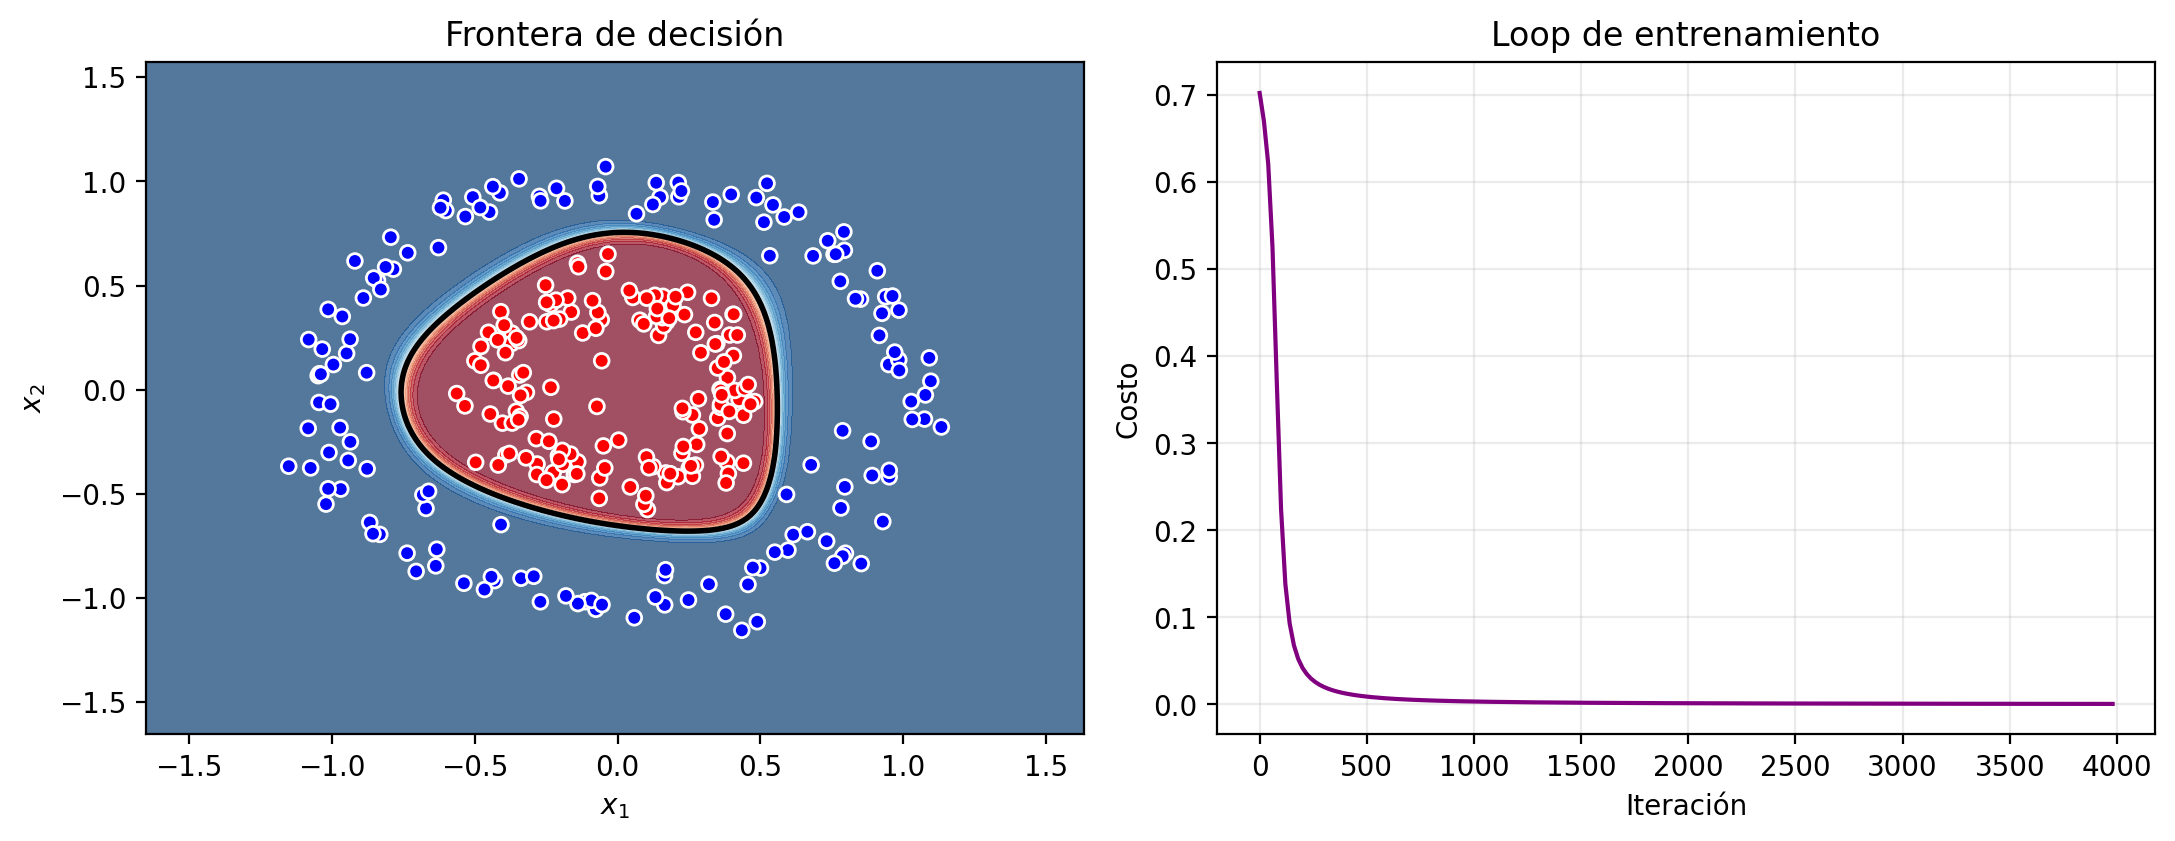

In [ ]:
eje_x1 = np.linspace(X[0].min() - 0.5, X[0].max() + 0.5, 240)
eje_x2 = np.linspace(X[1].min() - 0.5, X[1].max() + 0.5, 240)
malla_x1, malla_x2 = np.meshgrid(eje_x1, eje_x2)
X_malla = np.vstack((malla_x1.ravel(), malla_x2.ravel()))
AL_malla, _caches_malla = forward_propagation_deep(
    X_malla, parameters, activacion.value
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].contourf(
    malla_x1, malla_x2, AL_malla.reshape(malla_x1.shape),
    levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.7,
)
axes[0].contour(
    malla_x1, malla_x2, AL_malla.reshape(malla_x1.shape),
    levels=[0.5], colors="black", linewidths=2,
)
axes[0].scatter(X[0], X[1], c=Y.ravel(), cmap="bwr", edgecolor="white", s=28)
axes[0].set(title="Frontera de decisión", xlabel="$x_1$", ylabel="$x_2$")

pasos, valores = zip(*costs)
axes[1].plot(pasos, valores, color="purple")
axes[1].set(title="Loop de entrenamiento", xlabel="Iteración", ylabel="Costo")
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig

In [ ]:
formas_activaciones = [cache["A"].shape for cache in caches]
mo.callout(
    mo.md(
        f"""
        **Exactitud: {accuracy:.1%}**

        Arquitectura utilizada: `{layer_dims}`

        Formas de las activaciones: `{formas_activaciones}`

        Aún si el número de capas cambia, el loop exterior conserva las mismas cuatro etapas:
        forward propagation, costo (error), backpropagation y actualización de parámetros w,b.
        """
    ),
    kind="success" if accuracy >= 0.85 else "warn",
)

<marimo-callout-output data-html='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eExactitud: 100.0%\u003c/strong\u003e\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eArquitectura utilizada: \u003ccode\u003e[2, 6, 6, 1]\u003c/code\u003e\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eFormas de las activaciones: \u003ccode\u003e[(6, 300), (6, 300), (1, 300)]\u003c/code\u003e\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eAún si el número de capas cambia, el loop exterior conserva las mismas cuatro etapas:\nforward propagation, costo (error), backpropagation y actualización de parámetros w,b.\u003c/span\u003e\u003c/span\u003e"' data-kind='"success"'>

## De una capa oculta a una red profunda

Esta generalización que hicimos consistió en utilizar código previo específico para cada capa por ciclos que recorren una nueva variable `layer_dims`. Durante *forward propagation* se guardó un `cache` por capa. Durante el proceso de *backpropagation* recorremos estos valores en orden inverso aplicando regla de la cadena.

Tenemos que observar que más profundidad en una red neuronal no garantiza automáticamente un mejor resultado. El el proceso participan varias cosas:

- la función de activación
- la inicialización de los parámetros
- la tasa de aprendizaje (*learning rate*)
- el número de iteraciones
- la cantidad y calidad de los datos

### Preguntas

1. Mantén un número de neuronas constante y aumenta la profundidad.
2. Compara `tanh` y `ReLU` con la misma arquitectura.
3. Busca una configuración que no converja y explica la causa probable.
4. Calcula el número total de parámetros de la arquitectura seleccionada.
5. Relaciona cada función de este notebook con `Linear`, la activación, la
   función de pérdida y `optimizer.step()` en PyTorch (opcional).

## Respuestas

Para comparar con las mismas condiciones uso celdas con valores fijos en lugar de los controles.
Uso las funciones del notebook y sus valores por defecto: learning rate 0.4, 4000 iteraciones,
inicialización con semilla 21 y los mismos datos (300 puntos, semilla 18). Pruebo los dos
conjuntos, porque con los círculos casi todo llega a 100 % y las diferencias se ven mejor con
las lunas.

In [ ]:
def tabla_md(filas):
    """
    Argumentos:
    filas -- lista de diccionarios (una fila por diccionario)

    Retorna:
    texto de una tabla en markdown, para que se vea igual en marimo, Jupyter y GitHub
    """
    columnas = list(filas[0].keys())
    lineas = ["| " + " | ".join(columnas) + " |", "|" + "---|" * len(columnas)]
    for f in filas:
        lineas.append("| " + " | ".join(str(f[c]) for c in columnas) + " |")
    return "\n".join(lineas)

In [ ]:
def datos(nombre):
    """
    Argumentos:
    nombre -- "circulos" o "lunas"

    Retorna:
    X, Y con los mismos datos del notebook (observaciones en columnas)
    """
    if nombre == "circulos":
        _m, _e = make_circles(n_samples=300, noise=0.08, factor=0.42, random_state=18)
    else:
        _m, _e = make_moons(n_samples=300, noise=0.18, random_state=18)
    return _m.T, _e.reshape(1, -1)

def experimento(nombre, dims, activacion="tanh", learning_rate=0.4, iteraciones=4000):
    """
    Argumentos:
    nombre -- conjunto de datos
    dims -- layer_dims de la red
    activacion -- "tanh" o "relu"
    learning_rate, iteraciones -- parámetros del entrenamiento

    Retorna:
    diccionario con exactitud, costo final, neuronas muertas y parámetros
    """
    X_e, Y_e = datos(nombre)
    p, costos = nn_model_deep(X_e, Y_e, dims, activacion, iteraciones, learning_rate)
    AL_e, caches_e = forward_propagation_deep(X_e, p, activacion)
    # una neurona está "muerta" si vale cero para todos los puntos
    muertas = sum(int(np.sum(np.all(c["A"] == 0, axis=1))) for c in caches_e[:-1])
    return {"exactitud": float(np.mean((AL_e > 0.5) == Y_e)), "costo": float(costos[-1][1]),
            "muertas": muertas if activacion == "relu" else 0, "parametros": p, "costos": costos}

### 1. Mismo número de neuronas, más profundidad

La pregunta se puede leer de dos formas, así que probé las dos. Primero dejo fijas 6 neuronas
por capa y voy agregando capas. Después dejo fijo el total de neuronas ocultas en 12 y las
reparto en más capas.

In [ ]:
filas_1a = []
for _L in [1, 2, 3, 4]:
    _dims = [2] + [6] * _L + [1]
    _fila = {"Arquitectura": " → ".join(map(str, _dims))}
    for _c, _nom in [("circulos", "Círculos"), ("lunas", "Lunas")]:
        _r = experimento(_c, _dims)
        _fila[f"{_nom}: exactitud / costo"] = f"{_r['exactitud']:.1%} / {_r['costo']:.4f}"
    filas_1a.append(_fila)
filas_1b = []
for _dims in [[2, 12, 1], [2, 6, 6, 1], [2, 4, 4, 4, 1], [2, 3, 3, 3, 3, 1]]:
    _fila = {"Arquitectura (12 neuronas ocultas)": " → ".join(map(str, _dims))}
    for _act in ["tanh", "relu"]:
        _r = experimento("lunas", _dims, _act)
        _extra = f", {_r['muertas']} muertas" if _act == "relu" and _r["muertas"] else ""
        _fila[f"Lunas, {_act}"] = f"{_r['exactitud']:.1%} / {_r['costo']:.4f}{_extra}"
    filas_1b.append(_fila)
mo.vstack([
    mo.md("**a) 6 neuronas por capa, `tanh`** (exactitud / costo final)"),
    mo.md(tabla_md(filas_1a)),
    mo.md("**b) 12 neuronas ocultas en total, repartidas en más capas** (exactitud / costo final)"),
    mo.md(tabla_md(filas_1b)),
])

Arquitectura,Círculos: exactitud / costo,Lunas: exactitud / costo
2 → 6 → 1,100.0% / 0.0126,98.7% / 0.0250
2 → 6 → 6 → 1,100.0% / 0.0006,99.0% / 0.0178
2 → 6 → 6 → 6 → 1,100.0% / 0.0002,99.7% / 0.0086
2 → 6 → 6 → 6 → 6 → 1,100.0% / 0.0001,99.7% / 0.0074
Arquitectura (12 neuronas ocultas),"Lunas, tanh","Lunas, relu"
2 → 12 → 1,99.0% / 0.0244,99.3% / 0.0194
2 → 6 → 6 → 1,99.0% / 0.0178,99.3% / 0.0146
2 → 4 → 4 → 4 → 1,99.3% / 0.0088,"99.0% / 0.0204, 1 muertas"
2 → 3 → 3 → 3 → 3 → 1,99.7% / 0.0093,"89.7% / 0.2481, 2 muertas"


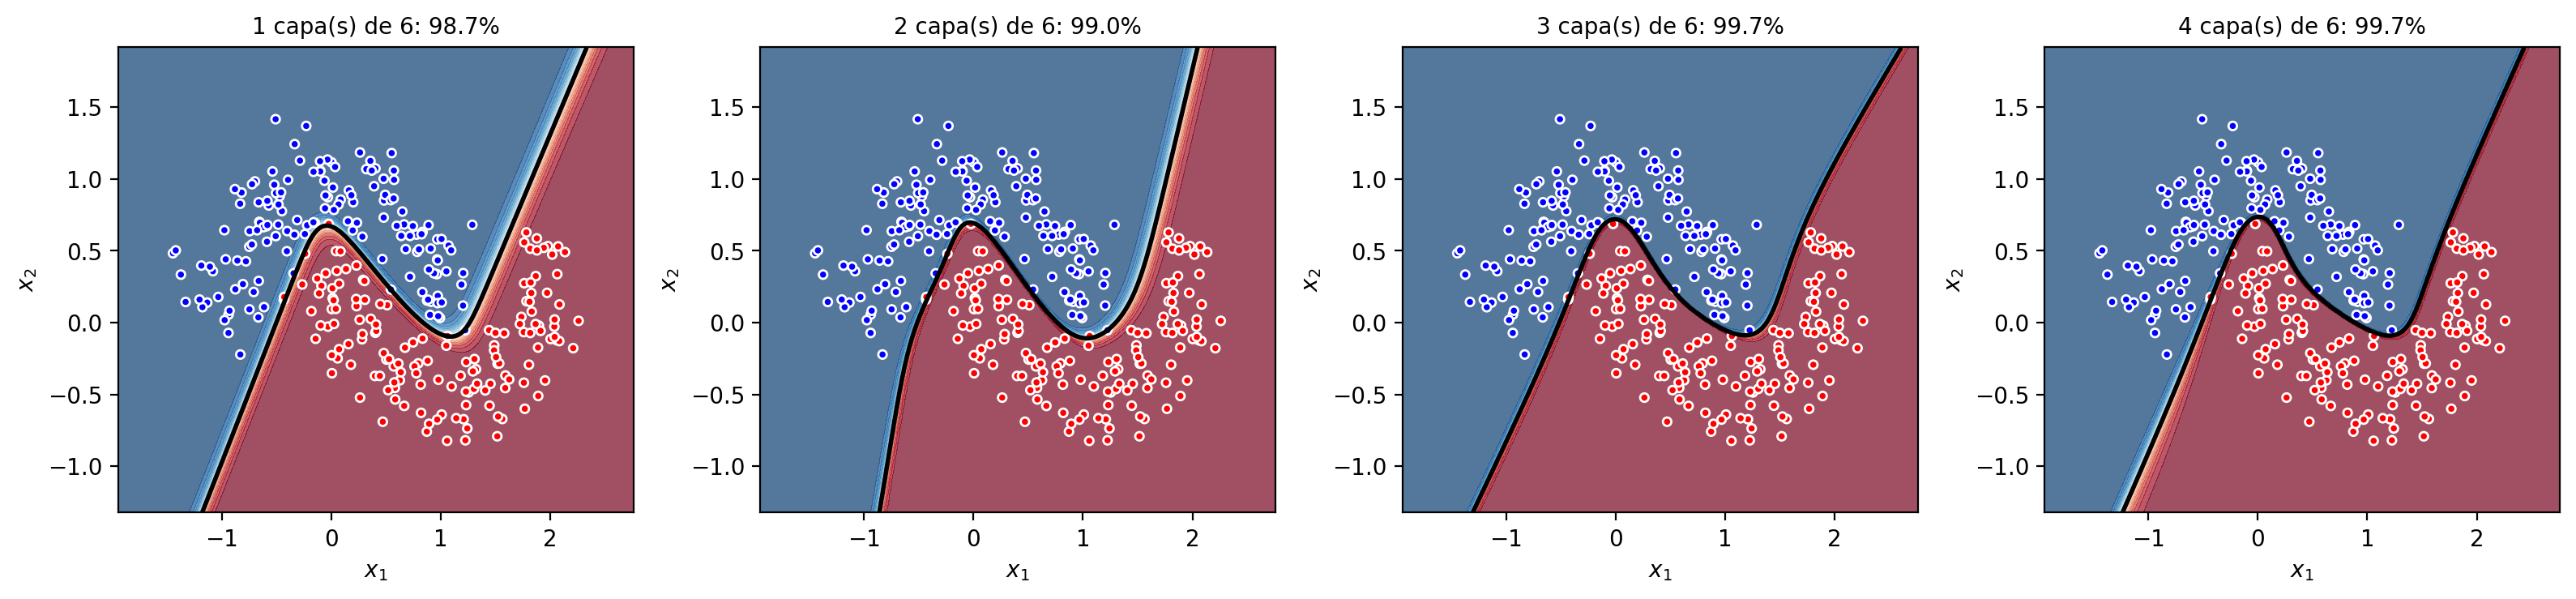

In [ ]:
_X, _Y = datos("lunas")
_g1, _g2 = np.meshgrid(np.linspace(_X[0].min() - 0.5, _X[0].max() + 0.5, 200),
                       np.linspace(_X[1].min() - 0.5, _X[1].max() + 0.5, 200))
_malla = np.vstack((_g1.ravel(), _g2.ravel()))
fig_1, ax_1 = plt.subplots(1, 4, figsize=(16, 3.8))
for _ax, _L in zip(ax_1, [1, 2, 3, 4]):
    _dims = [2] + [6] * _L + [1]
    _r = experimento("lunas", _dims)
    _a, _ = forward_propagation_deep(_malla, _r["parametros"], "tanh")
    _a = _a.reshape(_g1.shape)
    _ax.contourf(_g1, _g2, _a, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.7)
    _ax.contour(_g1, _g2, _a, levels=[0.5], colors="black", linewidths=2)
    _ax.scatter(_X[0], _X[1], c=_Y.ravel(), cmap="bwr", edgecolor="white", s=14)
    _ax.set_title(f"{_L} capa(s) de 6: {_r['exactitud']:.1%}", fontsize=10)
    _ax.set(xlabel="$x_1$", ylabel="$x_2$")
fig_1.tight_layout()
fig_1

Con los círculos todas las arquitecturas llegan a 100 %, así que la profundidad solo se nota en
el costo: baja de 0.0126 con una capa a 0.0001 con cuatro. La red ya clasificaba todo bien y lo
que gana con más capas es más "seguridad" en sus predicciones, que quedan más cerca de 0 y de 1.

Con las lunas, al dejar 6 neuronas por capa, la exactitud sube un poco de una a tres capas
(98.7 % a 99.7 %) y con cuatro ya no cambia. En la gráfica se ve que la frontera de una capa ya
es buena y que con más capas se ajusta más a los puntos de la orilla. La mejora es chica porque
con una capa ya casi estaba resuelto, y la cuarta capa no agrega nada.

Repartir las mismas 12 neuronas en más capas tampoco da una mejora clara. Con `tanh` sube un
poco de 99.0 % a 99.7 %, pero con `ReLU` la red de cuatro capas de 3 neuronas cae a 89.7 % y
tiene dos neuronas muertas. Cuando las capas son muy angostas, basta con que mueran una o dos
neuronas para que se pierda buena parte de la información que pasa a la siguiente capa. Mi
conclusión es que agregar profundidad no garantiza mejorar, como dice el texto del notebook:
ayuda hasta cierto punto y, si las capas se vuelven muy angostas, puede empeorar.

### 2. `tanh` contra `ReLU` con la misma arquitectura

In [ ]:
filas_2 = []
for _dims in [[2, 6, 1], [2, 6, 6, 1], [2, 6, 6, 6, 1], [2, 6, 6, 6, 6, 1]]:
    _fila = {"Arquitectura": " → ".join(map(str, _dims))}
    for _c, _nom in [("circulos", "Círculos"), ("lunas", "Lunas")]:
        for _act in ["tanh", "relu"]:
            _r = experimento(_c, _dims, _act)
            _fila[f"{_nom} {_act}"] = f"{_r['exactitud']:.1%}"
    _rr = experimento("lunas", _dims, "relu")
    _fila["Neuronas muertas (lunas, ReLU)"] = _rr["muertas"]
    filas_2.append(_fila)
mo.md(tabla_md(filas_2))

| Arquitectura | Círculos tanh | Círculos relu | Lunas tanh | Lunas relu | Neuronas muertas (lunas, ReLU) |
|---|---|---|---|---|---|
| 2 → 6 → 1 | 100.0% | 100.0% | 98.7% | 87.0% | 0 |
| 2 → 6 → 6 → 1 | 100.0% | 100.0% | 99.0% | 99.3% | 0 |
| 2 → 6 → 6 → 6 → 1 | 100.0% | 100.0% | 99.7% | 99.3% | 2 |
| 2 → 6 → 6 → 6 → 6 → 1 | 100.0% | 100.0% | 99.7% | 99.7% | 3 |

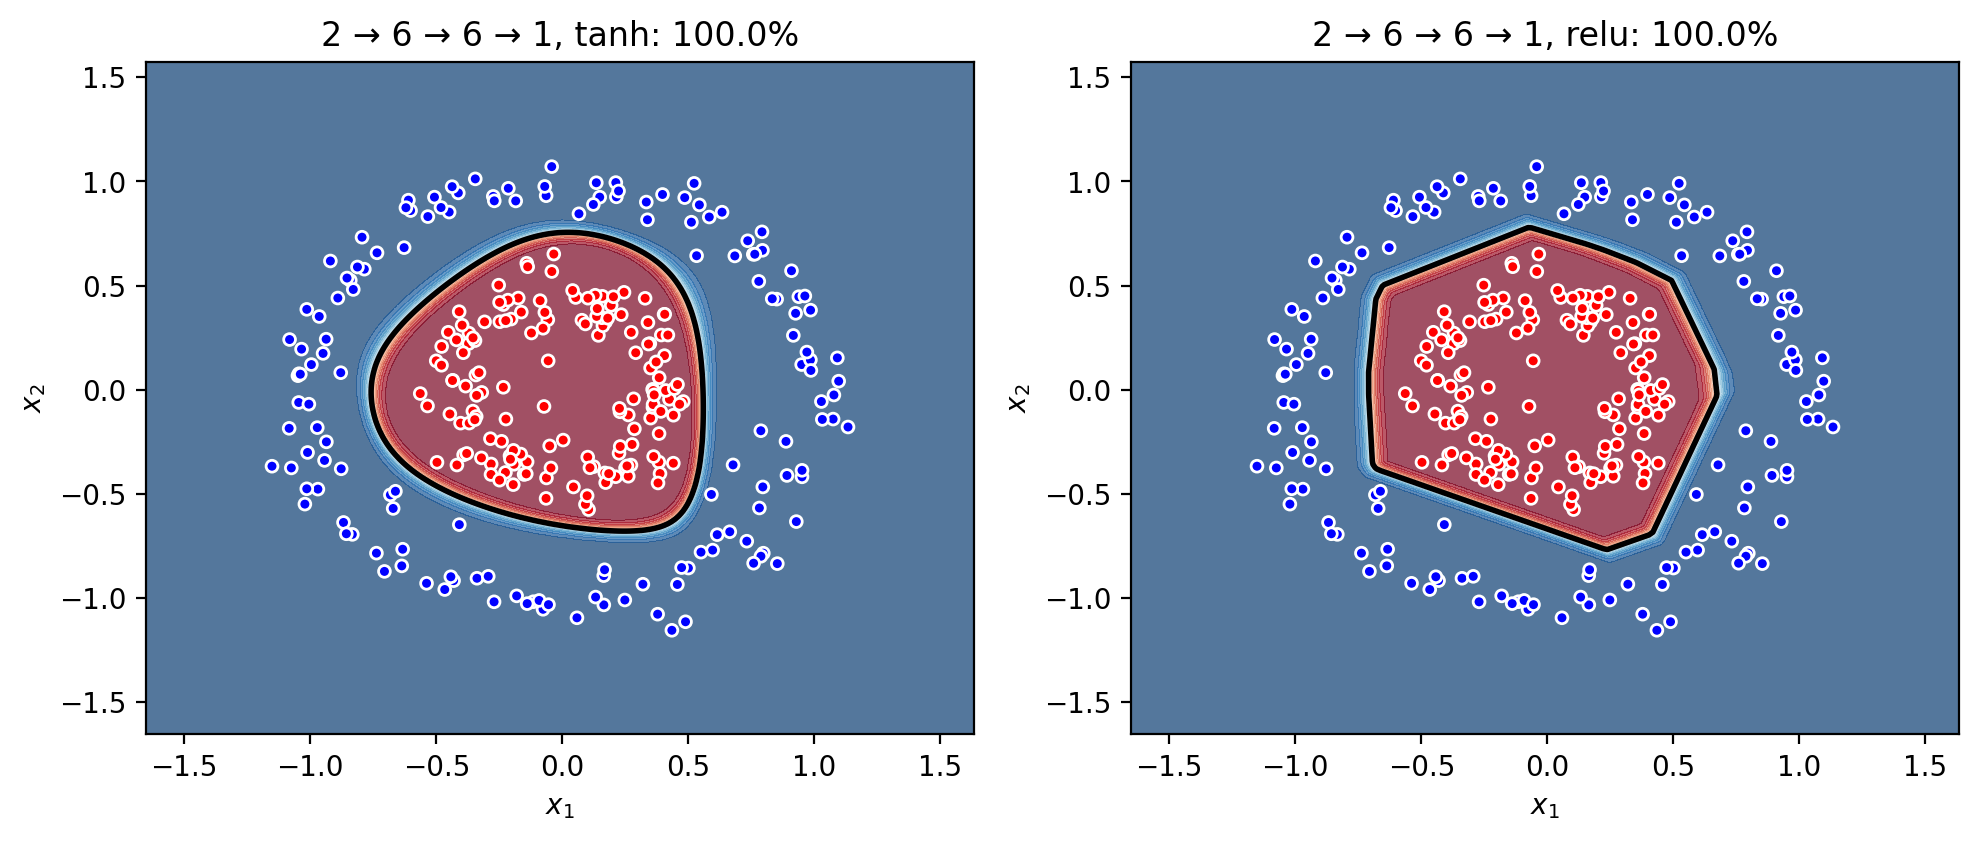

In [ ]:
_X, _Y = datos("circulos")
_g1, _g2 = np.meshgrid(np.linspace(_X[0].min() - 0.5, _X[0].max() + 0.5, 220),
                       np.linspace(_X[1].min() - 0.5, _X[1].max() + 0.5, 220))
_malla = np.vstack((_g1.ravel(), _g2.ravel()))
fig_2, ax_2 = plt.subplots(1, 2, figsize=(10, 4.3))
for _ax, _act in zip(ax_2, ["tanh", "relu"]):
    _r = experimento("circulos", [2, 6, 6, 1], _act)
    _a, _ = forward_propagation_deep(_malla, _r["parametros"], _act)
    _a = _a.reshape(_g1.shape)
    _ax.contourf(_g1, _g2, _a, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.7)
    _ax.contour(_g1, _g2, _a, levels=[0.5], colors="black", linewidths=2)
    _ax.scatter(_X[0], _X[1], c=_Y.ravel(), cmap="bwr", edgecolor="white", s=18)
    _ax.set(title=f"2 → 6 → 6 → 1, {_act}: {_r['exactitud']:.1%}", xlabel="$x_1$", ylabel="$x_2$")
fig_2.tight_layout()
fig_2

Con la arquitectura por defecto (2 → 6 → 6 → 1) las dos activaciones clasifican bien: 100 % en
los círculos y 99 % o más en las lunas. La diferencia más visible está en la forma de la
frontera. Con `tanh` el círculo sale redondo y suave; con `ReLU` sale como un polígono, con lados
rectos y esquinas, porque cada neurona `ReLU` es una función lineal por partes.

La otra diferencia es la estabilidad. Con una sola capa de 6 neuronas, `ReLU` se queda en 87.0 %
en las lunas mientras que `tanh` llega a 98.7 %, y al agregar capas aparecen neuronas muertas,
que valen cero para todos los puntos y ya no aprenden. `tanh` nunca tiene ese problema porque su
derivada no se hace cero de golpe. En redes de este tamaño `ReLU` no tiene ventaja; su ventaja
real aparece en redes mucho más profundas, donde `tanh` sufre más con el desvanecimiento del
gradiente que muestro en la siguiente pregunta.

### 3. Configuraciones que no convergen

Busqué combinaciones de arquitectura, activación y learning rate que se quedaran lejos de
clasificar bien, y encontré tres casos con causas distintas. Para ver la causa en cada uno
revisé el tamaño de los gradientes y si había neuronas muertas.

In [ ]:
_X, _Y = datos("circulos")
angosta = [2, 2, 2, 2, 2, 1]

def grad_max(p, activacion):
    """Retorna el valor absoluto más grande de dW en cada capa, para esos parámetros."""
    _AL, _ca = forward_propagation_deep(_X, p, activacion)
    _g = backward_propagation_deep(_AL, _Y, p, _ca, activacion)
    return [float(np.abs(_g[f"dW{_l}"]).max()) for _l in range(1, len(angosta))]

casos = [
    ("A. 2 → 6 → 6 → 1, tanh, lr 0.01, 500 it.", [2, 6, 6, 1], "tanh", 0.01, 500),
    ("B. 2 → 2 → 2 → 2 → 2 → 1, ReLU, lr 0.4", angosta, "relu", 0.4, 4000),
    ("C. 2 → 2 → 2 → 2 → 2 → 1, tanh, lr 0.4", angosta, "tanh", 0.4, 4000),
]
filas_3 = []
resultados_3 = {}
for _nombre, _dims, _act, _lr, _it in casos:
    _r = experimento("circulos", _dims, _act, _lr, _it)
    resultados_3[_nombre[0]] = _r
    _AL, _ = forward_propagation_deep(_X, _r["parametros"], _act)
    filas_3.append({"Caso": _nombre, "Exactitud": f"{_r['exactitud']:.1%}",
                    "Costo final": f"{_r['costo']:.4f}",
                    "Rango de las predicciones": f"{_AL.min():.3f} a {_AL.max():.3f}",
                    "Neuronas muertas": _r["muertas"]})
p0_relu = initialize_parameters_deep(angosta, "relu")
p0_tanh = initialize_parameters_deep(angosta, "tanh")
grads_b0 = grad_max(p0_relu, "relu")
grads_c0 = grad_max(p0_tanh, "tanh")
grads_c1 = grad_max(resultados_3["C"]["parametros"], "tanh")
_AL0, _ca0 = forward_propagation_deep(_X, p0_relu, "relu")
muertas_init = [int(np.sum(np.all(c["A"] == 0, axis=1))) for c in _ca0[:-1]]
mo.md(tabla_md(filas_3))

| Caso | Exactitud | Costo final | Rango de las predicciones | Neuronas muertas |
|---|---|---|---|---|
| A. 2 → 6 → 6 → 1, tanh, lr 0.01, 500 it. | 58.7% | 0.6816 | 0.401 a 0.612 | 0 |
| B. 2 → 2 → 2 → 2 → 2 → 1, ReLU, lr 0.4 | 50.0% | 0.6931 | 0.500 a 0.500 | 6 |
| C. 2 → 2 → 2 → 2 → 2 → 1, tanh, lr 0.4 | 27.7% | 0.6932 | 0.500 a 0.500 | 0 |

In [ ]:
mo.md(rf"""
**Caso A, learning rate muy chico con pocas iteraciones.** Es la arquitectura por defecto, que
con lr 0.4 llega a 100 %. Con 0.01 y 500 iteraciones se queda en 58.7 %, porque los pasos son tan
pequeños que no le da tiempo de llegar. No es un problema del modelo: con lr 0.4 converge.

**Caso B, neuronas `ReLU` muertas.** Con cuatro capas de 2 neuronas y `ReLU`, la red se queda en
50 % y el costo en 0.6931 = $\ln 2$, que es lo que da predecir 0.5 para todo. Revisé la red recién
inicializada, antes de entrenar, y las neuronas muertas por capa son {muertas_init}: desde la
segunda capa las dos neuronas valen cero para los 300 puntos. Con eso todo lo que llega a la
salida es cero, y como la derivada de `ReLU` también es cero, el gradiente de todas las capas
sale exactamente cero: el valor más grande de $dW$ en toda la red es {max(grads_b0):.1f}. La red no se mueve nunca, da igual
el learning rate o las iteraciones. Esto pasa porque las capas son tan angostas que basta con
que las dos neuronas queden del lado negativo para cortar toda la información.

**Caso C, desvanecimiento del gradiente.** La misma arquitectura con `tanh` no tiene neuronas
muertas, pero tampoco aprende: termina prediciendo 0.5 para todos los puntos. Al inicio el
gradiente de la primera capa ya es varias veces más chico que el de la última
({grads_c0[0]:.4f} contra {grads_c0[-1]:.4f}), porque en cada capa se multiplica por la derivada de
`tanh`, que es menor que 1. Después de entrenar todos los gradientes quedan alrededor de
{max(grads_c1):.0e}, prácticamente cero, y la red queda atorada en una solución que no separa
nada. La exactitud de este caso no significa mucho, porque todas las predicciones son 0.5 y
unas cuantas milésimas deciden de qué lado cae cada punto.

Lo que tienen en común B y C es que la red es profunda y muy angosta. Con la misma profundidad
pero 6 neuronas por capa, las dos activaciones llegan a 100 % (pregunta 1), así que el problema no
es la profundidad sola sino la combinación de muchas capas con muy pocas neuronas.
""")

**Caso A, learning rate muy chico con pocas iteraciones.** Es la arquitectura por defecto, que
con lr 0.4 llega a 100 %. Con 0.01 y 500 iteraciones se queda en 58.7 %, porque los pasos son tan
pequeños que no le da tiempo de llegar. No es un problema del modelo: con lr 0.4 converge.

**Caso B, neuronas `ReLU` muertas.** Con cuatro capas de 2 neuronas y `ReLU`, la red se queda en
50 % y el costo en 0.6931 = $\ln 2$, que es lo que da predecir 0.5 para todo. Revisé la red recién
inicializada, antes de entrenar, y las neuronas muertas por capa son [0, 2, 2, 2]: desde la
segunda capa las dos neuronas valen cero para los 300 puntos. Con eso todo lo que llega a la
salida es cero, y como la derivada de `ReLU` también es cero, el gradiente de todas las capas
sale exactamente cero: el valor más grande de $dW$ en toda la red es 0.0. La red no se mueve nunca, da igual
el learning rate o las iteraciones. Esto pasa porque las capas son tan angostas que basta con
que las dos neuronas queden del lado negativo para cortar toda la información.

**Caso C, desvanecimiento del gradiente.** La misma arquitectura con `tanh` no tiene neuronas
muertas, pero tampoco aprende: termina prediciendo 0.5 para todos los puntos. Al inicio el
gradiente de la primera capa ya es varias veces más chico que el de la última
(0.0088 contra 0.0680), porque en cada capa se multiplica por la derivada de
`tanh`, que es menor que 1. Después de entrenar todos los gradientes quedan alrededor de
4e-05, prácticamente cero, y la red queda atorada en una solución que no separa
nada. La exactitud de este caso no significa mucho, porque todas las predicciones son 0.5 y
unas cuantas milésimas deciden de qué lado cae cada punto.

Lo que tienen en común B y C es que la red es profunda y muy angosta. Con la misma profundidad
pero 6 neuronas por capa, las dos activaciones llegan a 100 % (pregunta 1), así que el problema no
es la profundidad sola sino la combinación de muchas capas con muy pocas neuronas.

### 4. Número total de parámetros

Cada capa $l$ tiene una matriz $W^{[l]}$ de $n_l \times n_{l-1}$ y un vector $b^{[l]}$ de $n_l$, así que
el total es

$$\text{parámetros} = \sum_{l=1}^{L} n_l\,(n_{l-1} + 1)$$

Para la arquitectura por defecto, $[2, 6, 6, 1]$:

- Capa 1: $6 \times 2 + 6 = 18$
- Capa 2: $6 \times 6 + 6 = 42$
- Capa 3: $1 \times 6 + 1 = 7$
- Total: $18 + 42 + 7 = 67$ parámetros.

Abajo lo comparo contra lo que cuenta el código para la arquitectura que esté seleccionada en
los controles y para las que usé en las preguntas anteriores.

In [ ]:
def contar_parametros(dims):
    """Aplica la fórmula: suma de n_l * (n_{l-1} + 1)."""
    return sum(dims[_l] * (dims[_l - 1] + 1) for _l in range(1, len(dims)))

_filas_4 = []
for _dims in [[2, 6, 6, 1], [2, 6, 1], [2, 6, 6, 6, 6, 1], [2, 12, 1], [2, 3, 3, 3, 3, 1],
              [2, 2, 2, 2, 2, 1], [2, 16, 16, 16, 16, 1]]:
    _filas_4.append({"Arquitectura": " → ".join(map(str, _dims)),
                     "Parámetros (fórmula)": contar_parametros(_dims)})
_en_codigo = sum(_v.size for _v in parameters.values())
mo.vstack([
    mo.md(f"**Arquitectura seleccionada en los controles: `{layer_dims}`**. Fórmula: "
          f"{contar_parametros(layer_dims)} parámetros; contados en el diccionario `parameters`: "
          f"{_en_codigo}."),
    mo.md(tabla_md(_filas_4)),
])

Arquitectura,Parámetros (fórmula)
2 → 6 → 6 → 1,67
2 → 6 → 1,25
2 → 6 → 6 → 6 → 6 → 1,151
2 → 12 → 1,49
2 → 3 → 3 → 3 → 3 → 1,49
2 → 2 → 2 → 2 → 2 → 1,27
2 → 16 → 16 → 16 → 16 → 1,881


Los dos conteos coinciden. Algo que me llamó la atención es cómo crece el número: las capas
intermedias pesan mucho más que la primera y la última, porque su matriz es de $n \times n$. Por
ejemplo, las 12 neuronas en una sola capa usan 49 parámetros, y repartidas en cuatro capas de 3
usan también 49; pero cuatro capas de 16 ya son 881. Pasar de una capa de 6 (25 parámetros) a
cuatro capas de 6 (151) multiplica los parámetros por seis, y en la pregunta 1 eso no mejoró la
exactitud de forma importante. Agregar ancho a capas intermedias hace crecer los parámetros
mucho más rápido que agregar capas angostas.

### 5. Relación con PyTorch (opcional)

En PyTorch cada parte de este notebook ya viene hecha. La relación que encontré es esta:

| Este notebook | PyTorch | Qué hace |
|---|---|---|
| `initialize_parameters_deep` con `layer_dims` | `nn.Linear(n_anterior, n_actual)` por capa | Cada `Linear` crea su `W` y su `b` y los inicializa |
| `parameters[f"W{l}"] @ A + parameters[f"b{l}"]` | `nn.Linear(...)(A)` | La parte lineal $Z = WA + b$ |
| `hidden_activation` (`tanh` / `ReLU`) | `nn.Tanh()` / `nn.ReLU()` | La activación de las capas ocultas |
| `sigmoid` en la última capa | `nn.Sigmoid()` | La salida como probabilidad |
| `forward_propagation_deep` | `model(X)` con `nn.Sequential` | Aplica todas las capas en orden |
| `compute_cost_deep` | `nn.BCELoss()` | Entropía cruzada binaria |
| `backward_propagation_deep` | `loss.backward()` | Calcula todos los gradientes con la regla de la cadena |
| `update_parameters_deep` | `optimizer.step()` con `torch.optim.SGD` | $W \leftarrow W - \alpha\,dW$ para todos los parámetros |
| (se vuelven a calcular desde cero cada vez) | `optimizer.zero_grad()` | Borra los gradientes de la iteración anterior |

La red por defecto se escribiría así (no lo ejecuto porque PyTorch todavía no está en mi
entorno, lo vemos en el siguiente tema):

```python
model = nn.Sequential(
    nn.Linear(2, 6), nn.Tanh(),
    nn.Linear(6, 6), nn.Tanh(),
    nn.Linear(6, 1), nn.Sigmoid(),
)
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.4)

for i in range(4000):
    y_hat = model(X)              # forward_propagation_deep
    loss = loss_fn(y_hat, Y)      # compute_cost_deep
    optimizer.zero_grad()
    loss.backward()               # backward_propagation_deep
    optimizer.step()              # update_parameters_deep
```

Dos diferencias que vale la pena notar. PyTorch usa la convención contraria a la de la clase:
las observaciones van en las **filas**, así que `X` tendría forma $(m, 2)$ en lugar de $(2, m)$.
Y `loss.backward()` no necesita que guardemos un `cache`, porque PyTorch registra las
operaciones mientras se hace el forward y de ahí calcula las derivadas solo.

### Conclusión

Generalizar con `layer_dims` permite cambiar la profundidad sin reescribir el código, pero más
capas no significan mejor resultado. En estos datos una o dos capas ya bastan, y las redes
profundas y angostas fallan por neuronas `ReLU` muertas o por desvanecimiento del gradiente con
`tanh`. Lo que importa es que la arquitectura, la activación, la inicialización y el learning
rate funcionen juntos.